In [2]:
%pip install -q numpy pandas matplotlib nltk scikit-learn gensim datasets

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 45.6 MB/s eta 0:00:00


# Content-Based Product Recommendation: Text Similarity Metrics x Vectorizers
Partial reproduction of Oprea et al., *A Comprehensive Analysis of Text Similarity Metrics and
Vectorization Techniques for Content-Based Product Recommendation* (IEEE Access, 2026).
Dataset: `bprateek/amazon_product_description` (Hugging Face).



In [3]:
# Config & imports
import re, time, os
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import CountVectorizer
from gensim.models import Word2Vec
import gensim.downloader as api
from datasets import load_dataset

SEED = 42
K = 10
N_SEEDS = 500
N_BOOT = 1000
GLOVE_NAME = "glove-wiki-gigaword-100"   # use "glove-wiki-gigaword-300" if you want 300d
W2V_KW = dict(vector_size=300, window=5, sg=1, negative=5, min_count=1,
              epochs=25, seed=SEED, workers=1)   # workers=1 -> deterministic
OUT_DIR = "results"
os.makedirs(OUT_DIR, exist_ok=True)

np.random.seed(SEED)
for pkg in ("stopwords", "wordnet", "omw-1.4"):
    nltk.download(pkg, quiet=True)

In [4]:
# 1. Load & clean dataset
ds = load_dataset("bprateek/amazon_product_description", split="train")
df = ds.to_pandas()
df = df.dropna(subset=["Product Name"]).copy()
df = df[df["Product Name"].str.strip() != "-"].reset_index(drop=True)   # drop '-' placeholder rows

stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()


def clean_text(text, remove_stops=True, lemmatize=True):
    """Lowercase + strip punctuation; optionally remove stopwords and lemmatize."""
    if not isinstance(text, str):
        return ""
    tokens = re.sub(r"[^a-z0-9\s]", " ", text.lower()).split()
    if remove_stops:
        tokens = [t for t in tokens if t not in stop_words]
    if lemmatize:
        tokens = [lemmatizer.lemmatize(t) for t in tokens]
    return " ".join(tokens)


df["cleaned_name"] = df["Product Name"].apply(clean_text)
# "No cleaning" = lowercase + punctuation strip only (no stopword removal, no lemmatization)
df["uncleaned_name"] = df["Product Name"].apply(lambda x: clean_text(x, False, False))


def extract_subcat(cat_str):
    """Ground-truth relevance label = top-2 levels of the category hierarchy."""
    if not isinstance(cat_str, str) or not cat_str.strip():
        return "Unknown"
    parts = [p.strip() for p in cat_str.split("|")]
    return " | ".join(parts[:2]) if len(parts) >= 2 else parts[0]


df["sub_category"] = df["Category"].apply(extract_subcat)
subcat = df["sub_category"].to_numpy()
subcat_totals = df["sub_category"].value_counts().to_dict()
print(f"{len(df)} products, {df['sub_category'].nunique()} subcategories")

README.md:   0%|          | 0.00/28.0 [00:00<?, ?B/s]

marketing_sample_for_amazon_com-ecommerc(…): reconstructing file:   0%|          |  0.00B / 19.6MB            

marketing_sample_for_amazon_com-ecommerc(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/10002 [00:00<?, ? examples/s]

10001 products, 108 subcategories


In [5]:
# 2. From-scratch building blocks (paper Eq. 1-8)
def cosine_sim_scratch(A, B):
    dot = A @ B.T
    na = np.linalg.norm(A, axis=1, keepdims=True)
    nb = np.linalg.norm(B, axis=1, keepdims=True).T
    return dot / np.maximum(na * nb, 1e-10)


def manhattan_dist_scratch(A, B):
    out = np.zeros((A.shape[0], B.shape[0]), dtype=np.float32)
    for i, row in enumerate(A):
        out[i] = np.abs(B - row).sum(axis=1)
    return out


def euclidean_dist_scratch(A, B):
    a_sq = (A ** 2).sum(axis=1, keepdims=True)
    b_sq = (B ** 2).sum(axis=1, keepdims=True).T
    return np.sqrt(np.maximum(a_sq + b_sq - 2.0 * (A @ B.T), 0.0))


def build_vocab(docs, max_features):
    counts = Counter(w for d in docs for w in d.split()).most_common(max_features)
    return {w: i for i, (w, _) in enumerate(counts)}


class ScratchTFIDF:
    """TF = count/len(doc); IDF = log(N/df); rows L2-normalised. Vocabulary is injected so it can
    be matched to the Count Vectorizer baseline (removes a vocabulary confound)."""

    def __init__(self, vocab):
        self.vocab = vocab

    def fit_transform(self, docs):
        tokenized = [d.split() for d in docs]
        N, V = len(tokenized), len(self.vocab)
        tf = np.zeros((N, V), dtype=np.float32)
        dfc = np.zeros(V, dtype=np.float32)
        for i, toks in enumerate(tokenized):
            if not toks:
                continue
            for w, c in Counter(toks).items():
                j = self.vocab.get(w)
                if j is not None:
                    tf[i, j] = c / len(toks)
                    dfc[j] += 1.0
        idf = np.log(N / np.maximum(dfc, 1.0))
        X = tf * idf
        return X / np.maximum(np.linalg.norm(X, axis=1, keepdims=True), 1e-10)


def pool_embeddings(docs, kv, mode="sum"):
    dim = kv.vector_size
    mat = np.zeros((len(docs), dim), dtype=np.float32)
    for i, doc in enumerate(docs):
        vecs = [kv[w] for w in doc.split() if w in kv.key_to_index]
        if vecs:
            mat[i] = np.sum(vecs, axis=0) if mode == "sum" else np.mean(vecs, axis=0)
    return mat


_zero_cache = {}


def zero_rows(X):
    """Boolean mask of all-zero (empty) document vectors, cached per matrix."""
    if id(X) not in _zero_cache:
        _zero_cache[id(X)] = ~np.any(X, axis=1)
    return _zero_cache[id(X)]


def retrieve_top_k(seed_idx, X, metric="cosine", k=K):
    """Top-k neighbours of seed_idx (seed excluded). Stable sort -> deterministic tie-breaking.
    Empty (all-zero) vectors are never valid neighbours: for L2-normalised data an all-zero row sits at
    Euclidean distance 1 from every query (i.e. looks like cosine 0.5) and would outrank real neighbours."""
    q = X[seed_idx:seed_idx + 1]
    if metric == "cosine":
        raw = cosine_sim_scratch(q, X)[0]
        key = -raw.astype(np.float64)
    elif metric == "manhattan":
        raw = manhattan_dist_scratch(q, X)[0]
        key = raw.astype(np.float64)
    elif metric == "euclidean":
        raw = euclidean_dist_scratch(q, X)[0]
        key = raw.astype(np.float64)
    else:
        raise ValueError(metric)
    key[zero_rows(X)] = np.inf
    key[seed_idx] = np.inf
    top = np.argsort(key, kind="stable")[:k]
    return top, raw[top]

In [6]:
# 3. Build representations (timed separately)
timings = {}

t0 = time.time()
cv = CountVectorizer(max_features=1500, min_df=5)
X_count = cv.fit_transform(df["cleaned_name"]).toarray().astype(np.float32)
timings["CountVec"] = time.time() - t0

shared_vocab = cv.vocabulary_                                  # identical vocabulary for fair comparison
t0 = time.time()
X_tfidf = ScratchTFIDF(shared_vocab).fit_transform(df["cleaned_name"])
timings["TF-IDF (shared vocab)"] = time.time() - t0

# Diagnostic: the earlier setup (top-3000 words, no min_df) - isolates the vocabulary confound
X_tfidf_3k = ScratchTFIDF(build_vocab(df["cleaned_name"], 3000)).fit_transform(df["cleaned_name"])

t0 = time.time()
w2v = Word2Vec(sentences=[d.split() for d in df["cleaned_name"]], **W2V_KW)
X_w2v = pool_embeddings(df["cleaned_name"], w2v.wv, "sum")
X_w2v_mean = pool_embeddings(df["cleaned_name"], w2v.wv, "mean")
timings["Word2Vec train+pool"] = time.time() - t0

t0 = time.time()
glove_kv = api.load(GLOVE_NAME)
timings["GloVe download/load"] = time.time() - t0
t0 = time.time()
X_glove = pool_embeddings(df["cleaned_name"], glove_kv, "sum")
timings["GloVe pool"] = time.time() - t0

print({k: f"{v:.1f}s" for k, v in timings.items()})
print("\nEmpty (all-zero) document vectors:")
for _n, _X in [("CountVec / TF-IDF (1500 vocab)", X_count), ("TF-IDF (3000 vocab)", X_tfidf_3k),
               ("Word2Vec", X_w2v), ("GloVe", X_glove)]:
    print(f"  {_n:32s} {zero_rows(_X).sum():5d} of {len(_X)} ({zero_rows(_X).mean():.1%})")

[==================================================] 100.0% 128.1/128.1MB downloaded
{'CountVec': '0.1s', 'TF-IDF (shared vocab)': '0.1s', 'Word2Vec train+pool': '16.8s', 'GloVe download/load': '71.2s', 'GloVe pool': '0.2s'}

Empty (all-zero) document vectors:
  CountVec / TF-IDF (1500 vocab)      82 of 10001 (0.8%)
  TF-IDF (3000 vocab)                 44 of 10001 (0.4%)
  Word2Vec                             0 of 10001 (0.0%)
  GloVe                                8 of 10001 (0.1%)


In [7]:
# 4. Case studies (Table 7 / Table 8)
test_patterns = {
    "Test1 (Puzzle)": r"Woodstock.*Collage.*500.*Puzzle",
    "Test2 (Longboard)": r"DB Longboards CoreFlex Crossbow",
    "Test3 (Costume)": r"Monster High Clawdeen Wolf Costume.*Small",
}
seed_ids = {}
for label, pat in test_patterns.items():
    m = df[df["Product Name"].str.contains(pat, case=False, regex=True, na=False)]
    assert len(m), f"No product matched for {label}"
    seed_ids[label] = m.index[0]
    print(f"{label} -> row {seed_ids[label]}: {df.loc[seed_ids[label], 'Product Name']!r}")

vec_dict = {"Count Vectorizer": X_count, "TF-IDF (Scratch)": X_tfidf,
            "Word2Vec (300d)": X_w2v, f"GloVe ({glove_kv.vector_size}d)": X_glove}

# Optional: paste the paper's Table 7 values here to get deltas, e.g. {("Count Vectorizer","cosine"): [a,b,c]}
PAPER_TABLE7 = PAPER_TABLE7 = {
 ("Count Vectorizer","cosine"):[0.51,0.47,0.8], ("Count Vectorizer","manhattan"):[5,8,3], ("Count Vectorizer","euclidean"):[2.24,2.83,1.73],
 ("TF-IDF (Scratch)","cosine"):[0.19,0.22,0.55], ("TF-IDF (Scratch)","manhattan"):[3.4,4.88,3.76], ("TF-IDF (Scratch)","euclidean"):[1.27,1.25,0.95],
 ("Word2Vec (300d)","cosine"):[0.85,0.81,0.91], ("Word2Vec (300d)","manhattan"):[63.32,109.61,65.01], ("Word2Vec (300d)","euclidean"):[4.55,7.82,4.64],
 ("GloVe (100d)","cosine"):[0.67,0.61,0.86], ("GloVe (100d)","manhattan"):[162.16,210.07,152.92], ("GloVe (100d)","euclidean"):[11.83,15.39,11.0],
}

rows = []
for v_name, Xm in vec_dict.items():
    for metric in ("cosine", "manhattan", "euclidean"):
        row = {"Vectorizer": v_name, "Metric": metric}
        vals = []
        for label, sid in seed_ids.items():
            _, sc = retrieve_top_k(sid, Xm, metric, k=1)
            row[label] = round(float(sc[0]), 3)
            vals.append(row[label])
        if (v_name, metric) in PAPER_TABLE7:
            row["max |delta vs paper|"] = round(float(np.max(np.abs(np.array(vals) - np.array(PAPER_TABLE7[(v_name, metric)])))), 3)
        rows.append(row)
df_t7 = pd.DataFrame(rows)
print("\nTABLE 7: 12-configuration top-1 scores (NOTE: raw scores are NOT comparable across "
      "vectorizers - see Table 11 for quality)")
print(df_t7.to_string(index=False))
df_t7.to_csv(f"{OUT_DIR}/table7.csv", index=False)

print("\nTABLE 8: Top-5 (Word2Vec + Cosine)")
for label, sid in seed_ids.items():
    print(f"\n[{label}] {df.loc[sid, 'Product Name']}")
    ti, ts = retrieve_top_k(sid, X_w2v, "cosine", 5)
    for r, (i, s) in enumerate(zip(ti, ts), 1):
        print(f"  {r}. ({s:.3f}) {df.loc[i, 'Product Name'][:70]} | {df.loc[i, 'sub_category']}")

Test1 (Puzzle) -> row 4: 'Woodstock- Collage 500 pc Puzzle'
Test2 (Longboard) -> row 0: 'DB Longboards CoreFlex Crossbow 41" Bamboo Fiberglass Longboard Complete'
Test3 (Costume) -> row 7399: "Rubie's Child's Monster High Clawdeen Wolf Costume, Small"

TABLE 7: 12-configuration top-1 scores (NOTE: raw scores are NOT comparable across vectorizers - see Table 11 for quality)
      Vectorizer    Metric  Test1 (Puzzle)  Test2 (Longboard)  Test3 (Costume)  max |delta vs paper|
Count Vectorizer    cosine           0.612              1.000            0.772                 0.530
Count Vectorizer manhattan           4.000              0.000            3.000                 8.000
Count Vectorizer euclidean           2.000              0.000            1.732                 2.830
TF-IDF (Scratch)    cosine           0.545              1.000            0.854                 0.780
TF-IDF (Scratch) manhattan           2.153              0.000            0.988                 4.880
TF-IDF (Scratch) e

In [8]:
# 5. Evaluation protocol (standard metrics + bootstrap CIs)
rng = np.random.default_rng(SEED)
EXCLUDE_EMPTY_SEEDS = True   # same seeds for every model; empty-vector queries have no meaningful ranking
ok = (subcat != "Unknown") & (np.array([subcat_totals.get(c, 0) for c in subcat]) >= 2)
if EXCLUDE_EMPTY_SEEDS:
    print(f"Seeds dropped because the Count/TF-IDF vector is empty: {(ok & zero_rows(X_count)).sum()}")
    ok &= ~zero_rows(X_count)
eligible = np.where(ok)[0]
seeds_500 = rng.choice(eligible, size=N_SEEDS, replace=False)
boot_idx = rng.integers(0, N_SEEDS, size=(N_BOOT, N_SEEDS))
DISC = 1.0 / np.log2(np.arange(2, K + 2))


def eval_seeds(seeds, X, metric="cosine", k=K):
    """Per-seed metrics. Relevant = same sub_category.
    Recall@K   = hits / (all other items in the sub_category)           [standard; small by construction]
    NDCG@K     = DCG / ideal DCG, ideal = min(K, #relevant in catalogue) relevant items at the top."""
    P, R, ND = [], [], []
    for s in seeds:
        top, _ = retrieve_top_k(s, X, metric, k)
        rel = (subcat[top] == subcat[s]).astype(np.float64)
        n_rel_total = subcat_totals[subcat[s]] - 1
        hits = rel.sum()
        P.append(hits / k)
        R.append(hits / n_rel_total)
        idcg = DISC[:min(k, n_rel_total)].sum()
        ND.append((rel * DISC[:len(rel)]).sum() / idcg)
    return {"P@10": np.array(P), "Recall@10": np.array(R), "NDCG@10": np.array(ND)}


def boot_ci(x):
    m = x[boot_idx].mean(axis=1)
    return np.percentile(m, [2.5, 97.5])


def summarise(results):
    rows = []
    for name, res in results.items():
        row = {"Model": name}
        for met, arr in res.items():
            lo, hi = boot_ci(arr)
            row[met] = round(float(arr.mean()), 3)
            row[met + " 95% CI"] = f"[{lo:.3f}, {hi:.3f}]"
        rows.append(row)
    return pd.DataFrame(rows)


def paired_delta(res_a, res_b, met="P@10"):
    """Bootstrap 95% CI of mean(a - b) on the same seeds. CI excluding 0 => difference is significant."""
    d = res_a[met] - res_b[met]
    lo, hi = np.percentile(d[boot_idx].mean(axis=1), [2.5, 97.5])
    return float(d.mean()), float(lo), float(hi)

Seeds dropped because the Count/TF-IDF vector is empty: 76


In [9]:
# 6. Main benchmark vs baseline
main_models = {
    "CountVec + Cosine (BASELINE)": (X_count, "cosine"),
    "TF-IDF + Cosine": (X_tfidf, "cosine"),
    "TF-IDF + Euclidean": (X_tfidf, "euclidean"),
    "TF-IDF (3000 vocab, no min_df) + Cosine": (X_tfidf_3k, "cosine"),
    "Word2Vec + Cosine": (X_w2v, "cosine"),
    f"GloVe-{glove_kv.vector_size}d + Cosine": (X_glove, "cosine"),
}
main_res = {n: eval_seeds(seeds_500, X, m) for n, (X, m) in main_models.items()}
df_main = summarise(main_res)
print("\nTABLE 11: 500-seed ranking metrics")
print(df_main.to_string(index=False))
df_main.to_csv(f"{OUT_DIR}/table11_main.csv", index=False)

# Sanity check: on L2-normalised vectors, Euclidean ranking == cosine ranking
same = np.mean([set(retrieve_top_k(s, X_tfidf, "cosine")[0]) == set(retrieve_top_k(s, X_tfidf, "euclidean")[0])
                for s in seeds_500])
print(f"\nTF-IDF: identical top-{K} sets under cosine vs Euclidean for {same:.1%} of seeds "
      "(expected ~100%: rows are unit-norm, so the metrics are monotonically related)")

print("\nPaired differences vs baseline (mean, 95% CI) on P@10:")
base = main_res["CountVec + Cosine (BASELINE)"]
for n, r in main_res.items():
    if n != "CountVec + Cosine (BASELINE)":
        d, lo, hi = paired_delta(r, base)
        print(f"  {n:45s} {d:+.3f}  [{lo:+.3f}, {hi:+.3f}]  {'significant' if lo > 0 or hi < 0 else 'n.s.'}")


TABLE 11: 500-seed ranking metrics
                                  Model  P@10    P@10 95% CI  Recall@10 Recall@10 95% CI  NDCG@10 NDCG@10 95% CI
           CountVec + Cosine (BASELINE) 0.514 [0.485, 0.544]      0.023   [0.019, 0.028]    0.539 [0.510, 0.568]
                        TF-IDF + Cosine 0.490 [0.463, 0.519]      0.023   [0.019, 0.029]    0.514 [0.485, 0.544]
                     TF-IDF + Euclidean 0.490 [0.463, 0.519]      0.023   [0.019, 0.029]    0.514 [0.485, 0.544]
TF-IDF (3000 vocab, no min_df) + Cosine 0.491 [0.462, 0.520]      0.025   [0.020, 0.031]    0.517 [0.487, 0.547]
                      Word2Vec + Cosine 0.538 [0.506, 0.571]      0.022   [0.019, 0.026]    0.558 [0.526, 0.591]
                    GloVe-100d + Cosine 0.409 [0.380, 0.439]      0.019   [0.015, 0.024]    0.443 [0.413, 0.472]

TF-IDF: identical top-10 sets under cosine vs Euclidean for 99.6% of seeds (expected ~100%: rows are unit-norm, so the metrics are monotonically related)

Paired difference

In [10]:
# 7. Ablation + improvement (all Word2Vec models share identical hyper-parameters)
# (a) no-cleaning: Word2Vec RETRAINED on un-cleaned tokens (otherwise stopwords/inflections are OOV)
w2v_unclean = Word2Vec(sentences=[d.split() for d in df["uncleaned_name"]], **W2V_KW)
X_w2v_unclean = pool_embeddings(df["uncleaned_name"], w2v_unclean.wv, "sum")

# (b) improvement: fuse Product Name + About Product (same W2V_KW as the default model)
df["fused_metadata"] = (df["Product Name"].fillna("") + " " + df["About Product"].fillna("")).apply(clean_text)
w2v_fused = Word2Vec(sentences=[d.split() for d in df["fused_metadata"]], **W2V_KW)
X_fused = pool_embeddings(df["fused_metadata"], w2v_fused.wv, "sum")
# (c) control: embeddings learned from fused corpus, but only the TITLE is pooled
#     -> separates "better embeddings" from "richer document representation"
X_fused_title_only = pool_embeddings(df["cleaned_name"], w2v_fused.wv, "sum")

ablation = {
    "1. Word2Vec + Cosine (default)": (X_w2v, "cosine"),
    "2. Euclidean (sum-pooled, unnormalised)": (X_w2v, "euclidean"),
    "3. Manhattan (sum-pooled, unnormalised)": (X_w2v, "manhattan"),
    "4. Euclidean (mean-pooled)": (X_w2v_mean, "euclidean"),
    "5. No text cleaning (W2V retrained)": (X_w2v_unclean, "cosine"),
    "6. Control: fused-corpus embeddings, title only": (X_fused_title_only, "cosine"),
    "7. IMPROVEMENT: Title + About Product": (X_fused, "cosine"),
}
ab_res = {n: eval_seeds(seeds_500, X, m) for n, (X, m) in ablation.items()}
df_ab = summarise(ab_res)
print("\nABLATION / IMPROVEMENT")
print(df_ab.to_string(index=False))
df_ab.to_csv(f"{OUT_DIR}/table_ablation.csv", index=False)

print("\nPaired differences vs default Word2Vec + Cosine (P@10):")
ref = ab_res["1. Word2Vec + Cosine (default)"]
for n, r in ab_res.items():
    if not n.startswith("1."):
        d, lo, hi = paired_delta(r, ref)
        print(f"  {n:50s} {d:+.3f}  [{lo:+.3f}, {hi:+.3f}]  {'significant' if lo > 0 or hi < 0 else 'n.s.'}")


ABLATION / IMPROVEMENT
                                          Model  P@10    P@10 95% CI  Recall@10 Recall@10 95% CI  NDCG@10 NDCG@10 95% CI
                 1. Word2Vec + Cosine (default) 0.538 [0.506, 0.571]      0.022   [0.019, 0.026]    0.558 [0.526, 0.591]
        2. Euclidean (sum-pooled, unnormalised) 0.511 [0.481, 0.543]      0.022   [0.018, 0.028]    0.531 [0.501, 0.563]
        3. Manhattan (sum-pooled, unnormalised) 0.511 [0.481, 0.543]      0.022   [0.018, 0.028]    0.532 [0.501, 0.563]
                     4. Euclidean (mean-pooled) 0.523 [0.491, 0.556]      0.021   [0.018, 0.025]    0.543 [0.513, 0.575]
            5. No text cleaning (W2V retrained) 0.528 [0.497, 0.559]      0.021   [0.018, 0.025]    0.548 [0.516, 0.581]
6. Control: fused-corpus embeddings, title only 0.560 [0.529, 0.592]      0.025   [0.021, 0.032]    0.583 [0.552, 0.615]
          7. IMPROVEMENT: Title + About Product 0.586 [0.556, 0.616]      0.025   [0.021, 0.030]    0.603 [0.572, 0.634]

Paired 

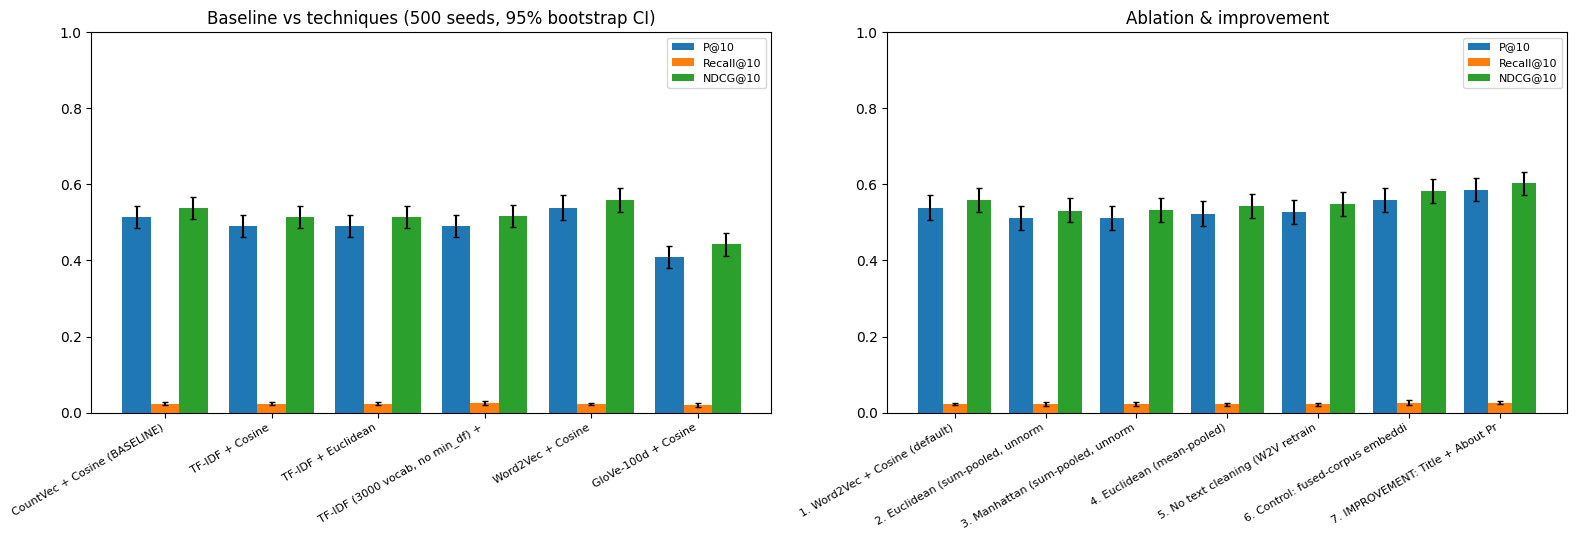

In [11]:
# 8. Plots
def grouped_bar(ax, results, metrics, title):
    names = list(results)
    w = 0.8 / len(metrics)
    for j, met in enumerate(metrics):
        means = np.array([results[n][met].mean() for n in names])
        cis = np.array([boot_ci(results[n][met]) for n in names])
        err = np.vstack([means - cis[:, 0], cis[:, 1] - means])
        ax.bar(np.arange(len(names)) + j * w, means, w, yerr=err, capsize=2, label=met)
    ax.set_xticks(np.arange(len(names)) + w * (len(metrics) - 1) / 2)
    ax.set_xticklabels([n[:32] for n in names], rotation=30, ha="right", fontsize=8)
    ax.set_ylim(0, 1)
    ax.set_title(title)
    ax.legend(fontsize=8)


fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
grouped_bar(axes[0], main_res, ["P@10", "Recall@10", "NDCG@10"], "Baseline vs techniques (500 seeds, 95% bootstrap CI)")
grouped_bar(axes[1], ab_res, ["P@10", "Recall@10", "NDCG@10"], "Ablation & improvement")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/PartC_Experimental_Results.png", dpi=300)
plt.show()

In [12]:
# 9. Computational footprint (for the report)
n_w2v = len(w2v.wv) * W2V_KW["vector_size"] * 2          # input + output (negative-sampling) matrices
print(f"Word2Vec vocab: {len(w2v.wv)} words, ~{n_w2v/1e6:.2f}M parameters (input+output)")
for name, X in [("CountVec", X_count), ("TF-IDF", X_tfidf), ("Word2Vec", X_w2v), ("GloVe", X_glove)]:
    print(f"  {name:10s} matrix {X.shape}, {X.nbytes/1e6:.1f} MB")
print("GPU: not required. Timings (s):", {k: round(v, 1) for k, v in timings.items()})

Word2Vec vocab: 13251 words, ~7.95M parameters (input+output)
  CountVec   matrix (10001, 1500), 60.0 MB
  TF-IDF     matrix (10001, 1500), 60.0 MB
  Word2Vec   matrix (10001, 300), 12.0 MB
  GloVe      matrix (10001, 100), 4.0 MB
GPU: not required. Timings (s): {'CountVec': 0.1, 'TF-IDF (shared vocab)': 0.1, 'Word2Vec train+pool': 16.8, 'GloVe download/load': 71.2, 'GloVe pool': 0.2}


# LIVE DEMO

In [17]:
def find_products(keyword, n=10):
    """Look up catalogue titles containing a keyword (to pick a demo query)."""
    m = df[df["Product Name"].str.contains(keyword, case=False, regex=False, na=False)].head(n)
    for i, r in m.iterrows():
        print(f"  [{i}] {r['Product Name'][:80]}")
    return m.index.tolist()


def recommend(query, k=5, model="w2v"):
    """query = product title (any text) or a row index. model = 'w2v' (selected) or 'count' (baseline)."""
    if isinstance(query, (int, np.integer)):
        text, exclude = df.loc[query, "Product Name"], {int(query)}
    else:
        text = query
        exclude = set(df.index[df["Product Name"].str.lower() == text.lower()])   # hide exact self-match
    clean_q = clean_text(text)
    if model == "w2v":
        X, qv = X_w2v, pool_embeddings([clean_q], w2v.wv, "sum")
    else:
        X, qv = X_count, cv.transform([clean_q]).toarray().astype(np.float32)
    if not qv.any():
        print("  (no known words in this query - try a different title)")
        return
    sims = cosine_sim_scratch(qv, X)[0]
    sims[zero_rows(X)] = -np.inf
    for i in exclude:
        sims[i] = -np.inf
    top = np.argsort(-sims, kind="stable")[:k]
    label = "Word2Vec + Cosine (selected)" if model == "w2v" else "CountVec + Cosine (baseline)"
    print(f"\n{label}  | cleaned query: '{clean_q}'")
    for r, i in enumerate(top, 1):
        print(f"  {r}. ({sims[i]:.3f}) {df.loc[i, 'Product Name'][:70]}  | {df.loc[i, 'sub_category']}")


def compare(query, k=5):
    print(f"QUERY: {query if not isinstance(query, (int, np.integer)) else df.loc[query, 'Product Name']}")
    recommend(query, k, "w2v")
    recommend(query, k, "count")


compare(seed_ids["Test3 (Costume)"])                      # a catalogue product by row index
compare("wwe")       # free-text query

QUERY: Rubie's Child's Monster High Clawdeen Wolf Costume, Small

Word2Vec + Cosine (selected)  | cleaned query: 'rubie child monster high clawdeen wolf costume small'
  1. (0.968) Rubies Monster High Clawdeen Wolf Child Costume Wig  | Clothing, Shoes & Jewelry | Costumes & Accessories
  2. (0.959) Monster High Deluxe Clawdeen Wolf Costume - Small  | Clothing, Shoes & Jewelry | Costumes & Accessories
  3. (0.955) Ever After High Blondie Lockes Costume, Child's Small  | Clothing, Shoes & Jewelry | Costumes & Accessories
  4. (0.951) Rubie's Monster High Haunted Spectra Vondergeist Child Costume Dress,   | Clothing, Shoes & Jewelry | Costumes & Accessories
  5. (0.950) Monster High Sweet 1600 Deluxe Draculaura Costume, Small  | Clothing, Shoes & Jewelry | Costumes & Accessories

CountVec + Cosine (baseline)  | cleaned query: 'rubie child monster high clawdeen wolf costume small'
  1. (0.772) Monster High Deluxe Clawdeen Wolf Costume - Small  | Clothing, Shoes & Jewelry | Costumes & Acces